# Exploratory Analysis of the Kaggle Payment Data

Four questions:

1. How imbalanced is the data, and in which transactions does fraud occur?
2. Which characteristics of a transaction distinguish fraudulent from legitimate payments?
3. Which columns cannot be used for modelling?
4. How does the data change over time, and how should it be split?

Merged data (after synthetic generation): `eda_merged.ipynb`. Figures: `reports/figures/eda/kaggle/`.

## Key findings

| Finding | Evidence | Implication |
|---|---|---|
| Fraud is rare and occurs in two transaction types only | 8,213 frauds out of 6,362,620 transactions (0.129%); all in TRANSFER (0.77%) and CASH_OUT (0.18%) | Imbalance handling is required; PAYMENT, CASH_IN and DEBIT carry no fraud signal |
| The effect of amount depends on the transaction type | CASH_OUT fraud rate reaches 5.7% in the top amount decile; TRANSFER fraud rate is highest for small amounts (1.8%) | Amount and type should be modelled jointly (tree-based models or an interaction term) |
| Losses are concentrated in a minority of cases | Frauds of at least 1 million are 32.9% of cases but 86.8% of the fraud value | Cost-based evaluation will be dominated by large frauds; recall should be reported by count and by value |
| High night-time fraud rates reflect missing legitimate activity | Fraud count is stable at 274 to 375 per hour; legitimate volume falls from 647,472 at 19:00 to 967 at 04:00 | Hour of day is informative, but the effect is partly a simulation artefact |
| Payments to first-time recipients are far riskier | Fraud rate 1.32% for first-time recipients against 0.09% to 0.19% otherwise | Recipient history features are the strongest legitimate signal (AUC up to 0.82) |
| Balance columns leak the label | 97.8% of frauds empty the sender account exactly, against 0.0% of legitimate transactions (AUC 0.989) | The four balance columns must be excluded from the model |
| Legitimate activity collapses after day 17 | From step 400 onwards: 9.5% of transactions but 45.7% of frauds | The final period is used as the stream; it contains a real shift in the fraud rate |

## Setup

In [1]:
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.csv as pv
import pyarrow.parquet as pq
import pyarrow.compute as pc
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.transforms as mtransforms
from sklearn.metrics import roc_auc_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())  # repo root
RAW_DIR = ROOT / "data" / "raw"
CSV_NAME = "PS_20174392719_1491204439457_log.csv"
CSV_PATH = RAW_DIR / CSV_NAME
ZIP_PATH = RAW_DIR / "kaggle dataset.zip"
PARQUET_PATH = RAW_DIR / "paysim.parquet"
FIG_DIR = ROOT / "reports" / "figures" / "eda" / "kaggle"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Colours: legitimate = blue, fraud = orange, de-emphasised = grey
LEGIT, FRAUD, MUTED = "#2a78d6", "#eb6834", "#c3c2b7"
TRANSFER_C, CASH_OUT_C = "#1baf7a", "#2a78d6"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.linewidth": 0.8, "axes.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "font.size": 10, "axes.titlesize": 10, "axes.titlecolor": INK2, "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2,
})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

def headline(fig, text):
    # The figure title states the finding; panel titles describe the measure.
    # Called after tight_layout, it sits just above the panel titles.
    top = max(ax.get_position().y1 for ax in fig.axes)
    shift = mtransforms.offset_copy(fig.transFigure, fig=fig, x=0, y=22, units="points")
    fig.text(0.01, top, text, transform=shift, ha="left", va="bottom", fontsize=13, fontweight="bold", color=INK)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

pct = mtick.PercentFormatter(decimals=1)

## Data loading

The CSV is converted once to parquet. Only the columns needed for each step are loaded, which keeps memory use low.

In [2]:
COLUMN_TYPES = {
    "step": pa.int16(), "type": pa.string(), "amount": pa.float64(),
    "nameOrig": pa.string(), "oldbalanceOrg": pa.float64(), "newbalanceOrig": pa.float64(),
    "nameDest": pa.string(), "oldbalanceDest": pa.float64(), "newbalanceDest": pa.float64(),
    "isFraud": pa.int8(), "isFlaggedFraud": pa.int8(),
}

def csv_to_parquet(f):
    reader = pv.open_csv(f, convert_options=pv.ConvertOptions(column_types=COLUMN_TYPES))
    with pq.ParquetWriter(PARQUET_PATH, reader.schema, compression="zstd") as writer:
        for batch in reader:
            writer.write_batch(batch)

if not PARQUET_PATH.exists():
    if CSV_PATH.exists():
        csv_to_parquet(CSV_PATH)
    else:
        with zipfile.ZipFile(ZIP_PATH) as zf, zf.open(CSV_NAME) as f:
            csv_to_parquet(f)

NUM_COLS = ["step", "type", "amount", "oldbalanceOrg", "newbalanceOrig",
            "oldbalanceDest", "newbalanceDest", "isFraud", "isFlaggedFraud"]
df = pd.read_parquet(PARQUET_PATH, columns=NUM_COLS)
df["type"] = df["type"].astype("category")
df["hour"] = (df.step % 24).astype("int8")          # assumes step 0 corresponds to midnight
df["day"] = ((df.step - 1) // 24 + 1).astype("int8")
print(f"{len(df):,} rows, {df.shape[1]} columns loaded")

6,362,620 rows, 11 columns loaded


## Data quality

In [3]:
pf = pq.ParquetFile(PARQUET_PATH)
hashes = np.concatenate([pd.util.hash_pandas_object(b.to_pandas(), index=False).to_numpy()
                         for b in pf.iter_batches(batch_size=500_000)])
n_dup = len(hashes) - len(np.unique(hashes))
del hashes

quality = pd.DataFrame({
    "check": ["Rows", "Columns", "Missing values", "Exact duplicate rows", "Negative amounts",
              "Zero amounts (all fraud)", "Steps covered", "Transaction types"],
    "result": [f"{len(df):,}", "11", f"{int(df[NUM_COLS].isna().sum().sum()):,}", f"{n_dup:,}",
               f"{(df.amount < 0).sum():,}",
               f"{(df.amount == 0).sum():,} ({int(df.loc[df.amount == 0, 'isFraud'].sum())} fraud)",
               f"{df.step.min()} to {df.step.max()} ({df.step.nunique()} distinct)",
               ", ".join(sorted(df.type.cat.categories))],
})
quality

,check,result
0,Rows,"6,362,620"
1,Columns,11
2,Missing values,0
3,Exact duplicate rows,0
4,Negative amounts,0
5,Zero amounts (all fraud),16 (16 fraud)
6,Steps covered,1 to 743 (743 distinct)
7,Transaction types,"CASH_IN, CASH_OUT, DEBIT, PAYMENT, TRANSFER"


The raw data contains no missing values, duplicates or negative amounts. The only irregularity is a set of 16 transactions with an amount of zero, all labelled as fraud; their treatment is left to the cleaning step. Because the Kaggle data is already clean, the cleaning module will mainly concern the synthetic fields.

## Account identifiers and recipient history

Recipient history is computed from earlier transactions only. Rows are ordered by `step`, and by file order within the same step. History covers all transaction types and the full timeline.

In [4]:
tbl = pq.read_table(PARQUET_PATH, columns=["nameOrig", "nameDest"])
n_orig_unique = pc.count_distinct(tbl["nameOrig"]).as_py()
dest = tbl["nameDest"].combine_chunks()
dest_code = dest.dictionary_encode().indices.to_numpy()
df["dest_is_merchant"] = pc.starts_with(dest, "M").to_numpy(zero_copy_only=False)
n_dest_unique = int(dest_code.max()) + 1
del tbl, dest

df["dest_prior_count"] = pd.Series(dest_code).groupby(dest_code).cumcount().to_numpy().astype("int32")
df["dest_steps_since_last"] = (df.step - df.step.groupby(dest_code).shift(1)).astype("float32")
df["is_new_dest"] = (df.dest_prior_count == 0).astype("int8")
del dest_code

print(f"Distinct senders (nameOrig):   {n_orig_unique:,} ({n_orig_unique / len(df):.2%} of rows)")
print(f"Distinct recipients (nameDest): {n_dest_unique:,}")
print(f"Frauds sent to merchants:       {int(df.loc[df.dest_is_merchant, 'isFraud'].sum())}")

Distinct senders (nameOrig):   6,353,307 (99.85% of rows)
Distinct recipients (nameDest): 2,722,362
Frauds sent to merchants:       0


Almost every sender appears only once, so sender-level behaviour (velocity, time since last purchase) cannot be derived from `nameOrig`; this motivates the synthetic `customer_id`. Recipients, by contrast, recur and provide a usable history. Merchant recipients (`M...`) never receive fraud.

## Class imbalance and transaction type

Frauds: 8,213 of 6,362,620 transactions (0.129%), about 774 legitimate transactions per fraud


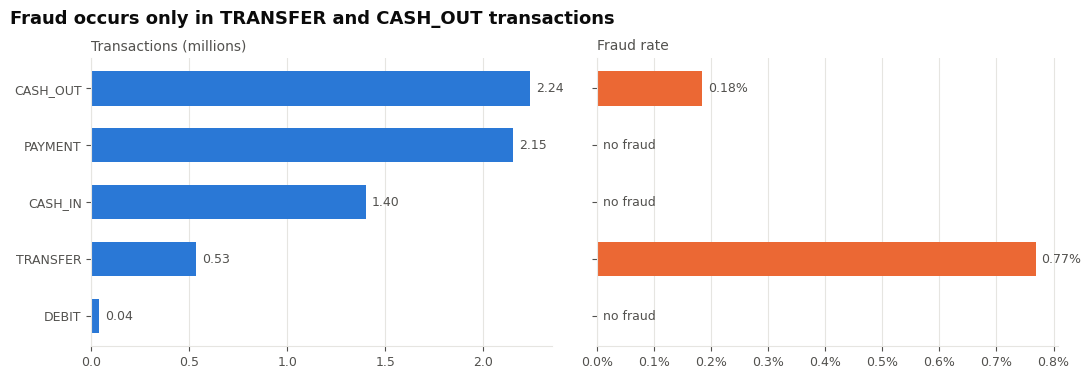

,transactions,frauds,fraud_rate
type,,,
DEBIT,41432,0,0.0000
TRANSFER,532909,4097,0.0077
CASH_IN,1399284,0,0.0000
PAYMENT,2151495,0,0.0000
CASH_OUT,2237500,4116,0.0018


In [5]:
n_fraud = int(df.isFraud.sum())
by_type = (df.groupby("type", observed=True)
             .agg(transactions=("isFraud", "size"), frauds=("isFraud", "sum"), fraud_rate=("isFraud", "mean"))
             .sort_values("transactions"))
print(f"Frauds: {n_fraud:,} of {len(df):,} transactions ({n_fraud / len(df):.3%}), "
      f"about {(len(df) - n_fraud) / n_fraud:,.0f} legitimate transactions per fraud")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
names = by_type.index.astype(str)
a1.barh(names, by_type.transactions / 1e6, color=LEGIT, height=0.6)
a1.set_title("Transactions (millions)")
a1.grid(axis="y", visible=False)
for y, v in enumerate(by_type.transactions / 1e6):
    a1.text(v + 0.03, y, f"{v:.2f}", va="center", fontsize=9, color=INK2)

colors = [FRAUD if r > 0 else MUTED for r in by_type.fraud_rate]
a2.barh(names, by_type.fraud_rate * 100, color=colors, height=0.6)
a2.set_title("Fraud rate")
a2.xaxis.set_major_formatter(pct)
a2.grid(axis="y", visible=False)
for y, r in enumerate(by_type.fraud_rate):
    a2.text(r * 100 + 0.01, y, f"{r:.2%}" if r > 0 else "no fraud", va="center", fontsize=9, color=INK2)
fig.tight_layout(); headline(fig, "Fraud occurs only in TRANSFER and CASH_OUT transactions"); save(fig, "type_volume_fraud_rate"); plt.show()
by_type

Fraud represents 0.129% of all transactions, roughly one fraud for every 774 legitimate payments. All frauds are TRANSFER or CASH_OUT operations, which follows the PaySim fraud scenario of taking over an account, transferring the balance and withdrawing it. TRANSFER is less frequent than CASH_OUT but four times riskier. Since the other three types contain no fraud, the following sections focus on TRANSFER and CASH_OUT (`tc`); including the other types would inflate every contrast.

In [6]:
tc = df[df.type.isin(["TRANSFER", "CASH_OUT"])].copy()
tc["type"] = tc["type"].cat.remove_unused_categories()
print(f"TRANSFER and CASH_OUT: {len(tc):,} transactions, fraud rate {tc.isFraud.mean():.3%} "
      f"(about {(tc.isFraud == 0).sum() / tc.isFraud.sum():,.0f} legitimate per fraud)")

TRANSFER and CASH_OUT: 2,770,409 transactions, fraud rate 0.296% (about 336 legitimate per fraud)


## Transaction amount

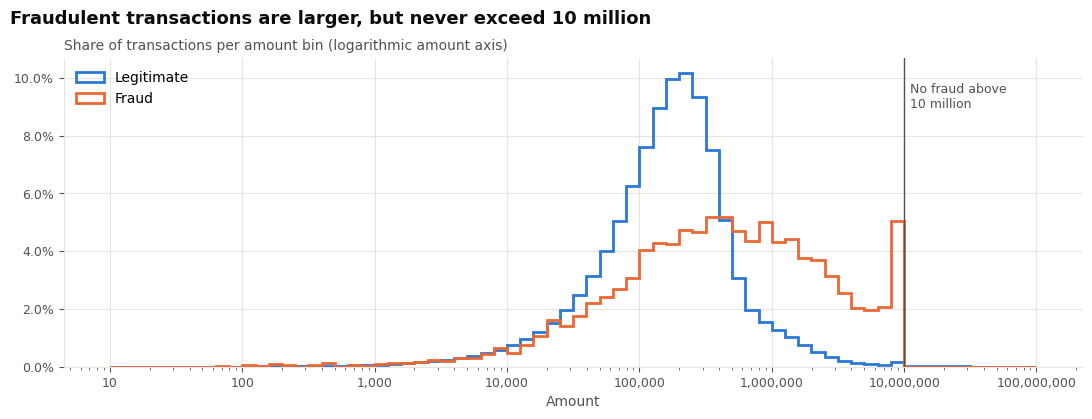

Frauds at exactly 10,000,000: 287; transactions above 10,000,000: 2,443, of which fraud: 0


,count,50%,mean,90%,max
isFraud,,,,,
legitimate,"2,762,196.0000","171,034.4600","314,115.4962","540,837.9200","92,445,516.6400"
fraud,"8,213.0000","441,423.4400","1,467,967.2991","4,521,723.5120","10,000,000.0000"


In [7]:
bins = np.logspace(1, 8, 71) * 1.0001   # 10 million falls just inside a bin edge
fig, ax = plt.subplots(figsize=(11, 4))
for label, color, name in [(0, LEGIT, "Legitimate"), (1, FRAUD, "Fraud")]:
    s = tc.loc[(tc.isFraud == label) & (tc.amount > 0), "amount"]
    ax.hist(s, bins=bins, weights=np.full(len(s), 100 / len(s)), histtype="step", lw=2, color=color, label=name)
ax.set_xscale("log")
ax.axvline(1e7, color=INK2, lw=1)
ax.text(1.1e7, ax.get_ylim()[1] * 0.92, "No fraud above\n10 million", fontsize=9, color=INK2, va="top")
ax.set_title("Share of transactions per amount bin (logarithmic amount axis)")
ax.set_xlabel("Amount")
ax.yaxis.set_major_formatter(pct)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(loc="upper left")
fig.tight_layout(); headline(fig, "Fraudulent transactions are larger, but never exceed 10 million"); save(fig, "amount_distribution"); plt.show()

summary = tc.groupby("isFraud").amount.describe(percentiles=[.5, .9]).rename(index={0: "legitimate", 1: "fraud"})
print(f"Frauds at exactly 10,000,000: {((tc.amount == 1e7) & (tc.isFraud == 1)).sum():,}; "
      f"transactions above 10,000,000: {(tc.amount > 1e7).sum():,}, of which fraud: {int(tc.loc[tc.amount > 1e7, 'isFraud'].sum())}")
summary[["count", "50%", "mean", "90%", "max"]]

The median fraud (441,423) is about 2.6 times the median legitimate transfer or withdrawal (171,034). Fraudulent amounts are capped at exactly 10 million, with 287 frauds at the cap, while 2,443 legitimate transactions exceed it. The cap is a property of the simulator; a tree-based model could learn that very large amounts are safe, which should be stated as a limitation.

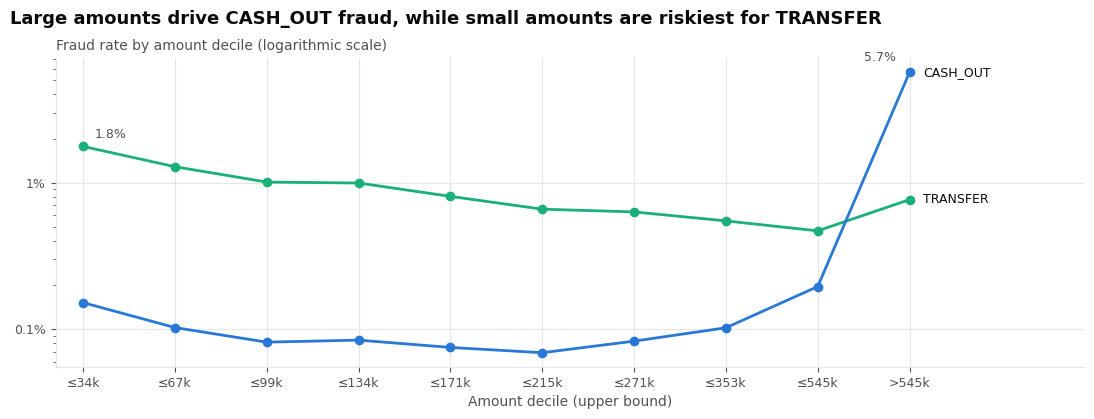

type,CASH_OUT,TRANSFER
amount_decile,,
"(-0.001, 34162.534]",0.1520,1.7670
"(34162.534, 66797.146]",0.1020,1.2840
"(66797.146, 99390.778]",0.0810,1.0090
"(99390.778, 133738.014]",0.0840,0.9940
"(133738.014, 171260.93]",0.0750,0.8060
"(171260.93, 215050.366]",0.0690,0.6590
"(215050.366, 270842.392]",0.0830,0.6310
"(270842.392, 352961.522]",0.1020,0.5480
"(352961.522, 544867.566]",0.1950,0.4690


In [8]:
tc["amount_decile"] = pd.qcut(tc.amount, 10)
dec = tc.groupby(["amount_decile", "type"], observed=True).isFraud.mean().unstack() * 100
upper = [iv.right for iv in dec.index]
labels = [f"≤{u/1e3:,.0f}k" for u in upper[:-1]] + [f">{upper[-2]/1e3:,.0f}k"]

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(dec))
for col, color in [("TRANSFER", TRANSFER_C), ("CASH_OUT", CASH_OUT_C)]:
    ax.plot(x, dec[col], marker="o", ms=6, color=color)
    ax.text(x[-1] + 0.15, dec[col].iloc[-1], col, color=INK, fontsize=9, va="center")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}%"))
ax.set_xticks(x, labels)
ax.set_xlim(-0.3, len(x) - 0.1 + 1.0)
ax.set_title("Fraud rate by amount decile (logarithmic scale)")
ax.set_xlabel("Amount decile (upper bound)")
ax.annotate(f"{dec['CASH_OUT'].iloc[-1]:.1f}%", (x[-1], dec["CASH_OUT"].iloc[-1]), textcoords="offset points",
            xytext=(-10, 8), ha="right", fontsize=9, color=INK2)
ax.annotate(f"{dec['TRANSFER'].iloc[0]:.1f}%", (x[0], dec["TRANSFER"].iloc[0]), textcoords="offset points",
            xytext=(8, 6), fontsize=9, color=INK2)
fig.tight_layout(); headline(fig, "Large amounts drive CASH_OUT fraud, while small amounts are riskiest for TRANSFER"); save(fig, "fraud_rate_by_amount_and_type"); plt.show()
dec.round(3)

Amount and type interact. For CASH_OUT, the fraud rate stays below 0.2% in the first nine deciles and jumps to 5.7% in the top decile. For TRANSFER, the fraud rate is highest for the smallest amounts (1.8%) and declines as the amount grows. A single global effect of amount would therefore be misleading; tree-based models capture this interaction directly, and a linear model would require an amount by type interaction term.

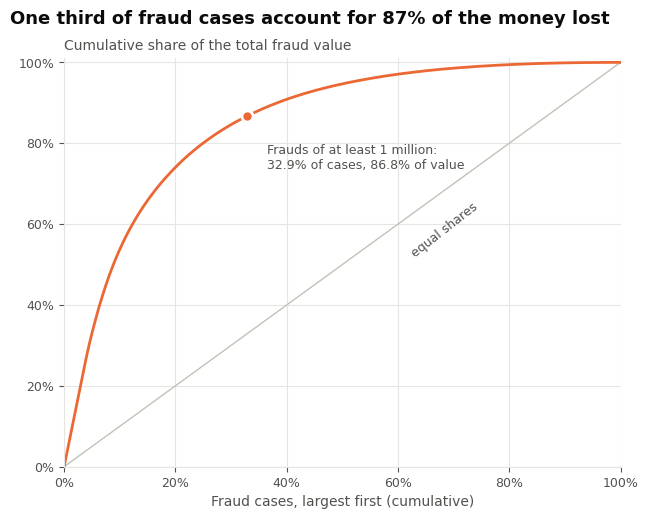

Total fraud value: 12,056,415,428; top 20% of cases: 74.0% of value


In [9]:
fa = np.sort(tc.loc[tc.isFraud == 1, "amount"].to_numpy())[::-1]
cum_cases = np.arange(1, len(fa) + 1) / len(fa) * 100
cum_value = np.cumsum(fa) / fa.sum() * 100
k = int((fa >= 1e6).sum())

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot([0, 100], [0, 100], color=MUTED, lw=1)
ax.plot(cum_cases, cum_value, color=FRAUD)
ax.plot(cum_cases[k - 1], cum_value[k - 1], "o", ms=8, color=FRAUD, mec="white", mew=2)
ax.annotate(f"Frauds of at least 1 million:\n{cum_cases[k-1]:.1f}% of cases, {cum_value[k-1]:.1f}% of value",
            (cum_cases[k - 1], cum_value[k - 1]), textcoords="offset points", xytext=(14, -38), fontsize=9, color=INK2)
ax.text(62, 52, "equal shares", color=INK2, fontsize=9, rotation=38)
ax.set_xlim(0, 100); ax.set_ylim(0, 101)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Fraud cases, largest first (cumulative)")
ax.set_title("Cumulative share of the total fraud value")
fig.tight_layout(); headline(fig, "One third of fraud cases account for 87% of the money lost"); save(fig, "fraud_value_concentration"); plt.show()
print(f"Total fraud value: {fa.sum():,.0f}; top 20% of cases: {cum_value[int(len(fa) * 0.2) - 1]:.1f}% of value")

Fraud losses are highly concentrated: frauds of at least 1 million make up 32.9% of the cases but 86.8% of the total fraud value of 12.06 billion. Under a cost matrix where a missed fraud costs its amount, the evaluation will be driven by these large cases. Recall should therefore be reported both by number of cases and by value caught.

## Time patterns

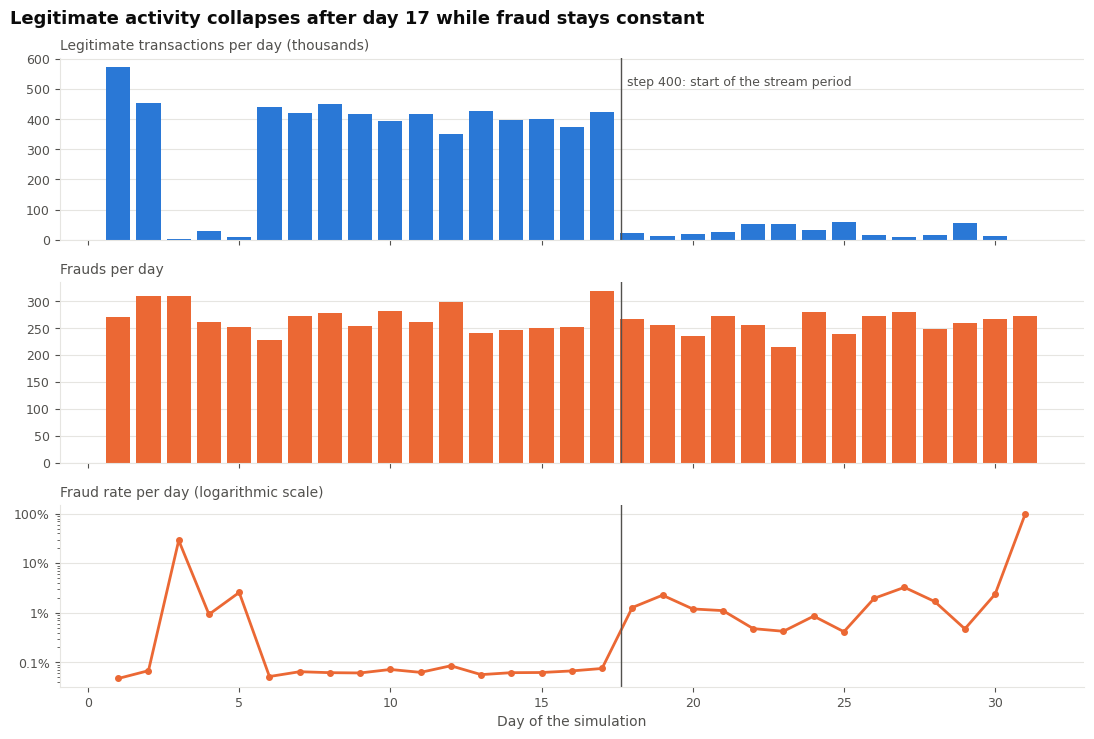

From step 400: 9.5% of transactions, 45.7% of frauds; fraud rate 0.078% before and 0.619% after
Frauds per day: 216 to 320; days without legitimate transactions: [31]


In [10]:
daily = df.groupby("day").agg(legit=("isFraud", lambda s: int((s == 0).sum())), fraud=("isFraud", "sum"))
daily["fraud_rate"] = daily.fraud / (daily.legit + daily.fraud) * 100
split_day = (400 - 1) / 24 + 1   # position of step 400 on the day axis

fig, axes = plt.subplots(3, 1, figsize=(11, 7.2), sharex=True)
axes[0].bar(daily.index, daily.legit / 1e3, color=LEGIT, width=0.8)
axes[0].set_title("Legitimate transactions per day (thousands)")
axes[1].bar(daily.index, daily.fraud, color=FRAUD, width=0.8)
axes[1].set_title("Frauds per day")
axes[2].plot(daily.index, daily.fraud_rate, color=FRAUD, marker="o", ms=4)
axes[2].set_yscale("log")
axes[2].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}%"))
axes[2].set_title("Fraud rate per day (logarithmic scale)")
axes[2].set_xlabel("Day of the simulation")
for ax in axes:
    ax.axvline(split_day, color=INK2, lw=1)
    ax.grid(axis="x", visible=False)
axes[0].text(split_day + 0.2, axes[0].get_ylim()[1] * 0.85, "step 400: start of the stream period", fontsize=9, color=INK2)
fig.tight_layout(); headline(fig, "Legitimate activity collapses after day 17 while fraud stays constant"); save(fig, "volume_fraud_by_day"); plt.show()

late = df.step >= 400
print(f"From step 400: {late.mean():.1%} of transactions, {df.loc[late, 'isFraud'].sum() / n_fraud:.1%} of frauds; "
      f"fraud rate {df.loc[~late, 'isFraud'].mean():.3%} before and {df.loc[late, 'isFraud'].mean():.3%} after")
print(f"Frauds per day: {daily.fraud.min()} to {daily.fraud.max()}; days without legitimate transactions: {list(daily.index[daily.legit == 0])}")

Frauds are generated at a steady pace of 216 to 320 per day over the 31 days, whereas legitimate activity is concentrated in days 1 to 17, with much lower volumes on days 3 to 5 and no legitimate transaction at all on day 31. From step 400 onwards, the data contains 9.5% of all transactions but 45.7% of all frauds, and the fraud rate rises from 0.078% to 0.619%. This shift is a property of the simulation, not a change in fraud behaviour, and it determines the choice of split points below.

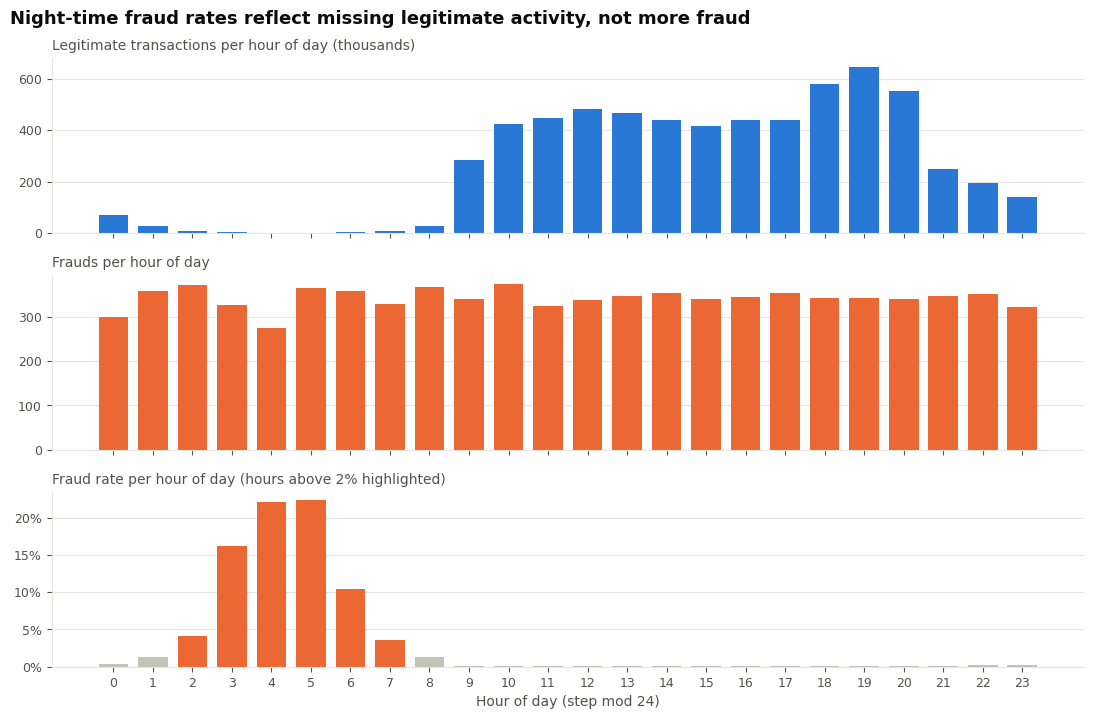

Frauds per hour: 274 to 375; legitimate per hour: 967 (hour 4) to 647,472 (hour 19)


In [11]:
hourly = df.groupby("hour").agg(legit=("isFraud", lambda s: int((s == 0).sum())), fraud=("isFraud", "sum"))
hourly["fraud_rate"] = hourly.fraud / (hourly.legit + hourly.fraud) * 100
night = hourly.fraud_rate >= 2

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
axes[0].bar(hourly.index, hourly.legit / 1e3, color=LEGIT, width=0.75)
axes[0].set_title("Legitimate transactions per hour of day (thousands)")
axes[1].bar(hourly.index, hourly.fraud, color=FRAUD, width=0.75)
axes[1].set_title("Frauds per hour of day")
axes[2].bar(hourly.index, hourly.fraud_rate, color=[FRAUD if n else MUTED for n in night], width=0.75)
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[2].set_title("Fraud rate per hour of day (hours above 2% highlighted)")
axes[2].set_xticks(range(24))
axes[2].set_xlabel("Hour of day (step mod 24)")
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.tight_layout(); headline(fig, "Night-time fraud rates reflect missing legitimate activity, not more fraud"); save(fig, "volume_fraud_by_hour"); plt.show()
print(f"Frauds per hour: {hourly.fraud.min()} to {hourly.fraud.max()}; legitimate per hour: "
      f"{hourly.legit.min():,} (hour {hourly.legit.idxmin()}) to {hourly.legit.max():,} (hour {hourly.legit.idxmax()})")

The number of frauds is nearly constant across the day (274 to 375 per hour), whereas legitimate activity ranges from 967 transactions at 04:00 to 647,472 at 19:00. The resulting fraud rate exceeds 2% between 02:00 and 07:00 and reaches 22% at 05:00. Hour of day is therefore a useful feature, encoded cyclically or as a night indicator, but the strength of the effect stems from the simulator and is likely weaker in real data.

## Balance columns and label leakage

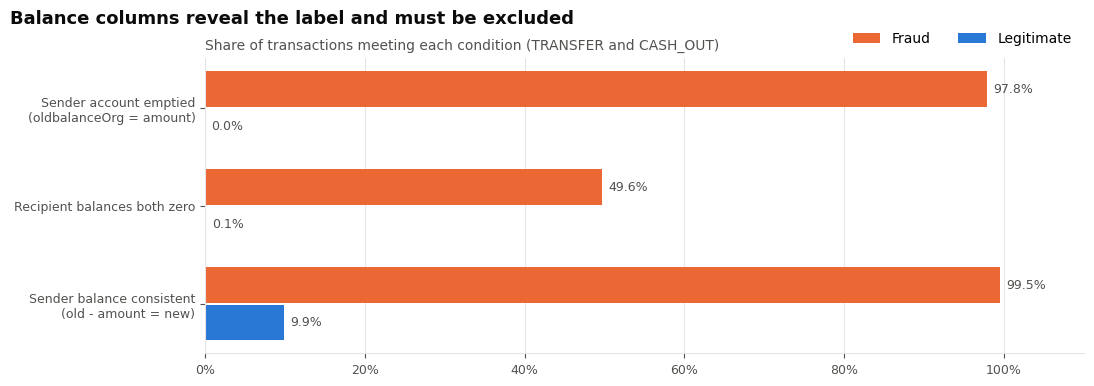

,Legitimate,Fraud
Sender account emptied\n(oldbalanceOrg = amount),0.0000,97.8200
Recipient balances both zero,0.0600,49.6300
Sender balance consistent\n(old - amount = new),9.9000,99.4500


In [12]:
conditions = {
    "Sender account emptied\n(oldbalanceOrg = amount)": tc.oldbalanceOrg == tc.amount,
    "Recipient balances both zero": (tc.oldbalanceDest == 0) & (tc.newbalanceDest == 0),
    "Sender balance consistent\n(old - amount = new)": pd.Series(
        np.isclose(tc.oldbalanceOrg - tc.amount, tc.newbalanceOrig, atol=0.01), index=tc.index),
}
leak = pd.DataFrame({k: v.groupby(tc.isFraud).mean() * 100 for k, v in conditions.items()}).T
leak.columns = ["Legitimate", "Fraud"]

fig, ax = plt.subplots(figsize=(11, 3.8))
y = np.arange(len(leak))
ax.barh(y + 0.19, leak["Legitimate"], height=0.36, color=LEGIT, label="Legitimate")
ax.barh(y - 0.19, leak["Fraud"], height=0.36, color=FRAUD, label="Fraud")
for i, (l, f) in enumerate(zip(leak["Legitimate"], leak["Fraud"])):
    ax.text(l + 0.8, i + 0.19, f"{l:.1f}%", va="center", fontsize=9, color=INK2)
    ax.text(f + 0.8, i - 0.19, f"{f:.1f}%", va="center", fontsize=9, color=INK2)
ax.set_yticks(y, leak.index)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlim(0, 110)
ax.grid(axis="y", visible=False)
ax.set_title("Share of transactions meeting each condition (TRANSFER and CASH_OUT)")
h, l = ax.get_legend_handles_labels()
ax.legend(h[::-1], l[::-1], loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2)
fig.tight_layout(); headline(fig, "Balance columns reveal the label and must be excluded"); save(fig, "balance_leakage"); plt.show()
leak.round(2)

In 97.8% of frauds the transferred amount equals the sender balance exactly, which never happens in legitimate transactions, and half of the frauds show zero balances on the recipient side. The sender balance is also arithmetically consistent in 99.5% of frauds but in only 9.9% of legitimate transactions, whose recorded balances often do not add up. These patterns arise because the simulator cancels fraudulent transactions, as stated in the PaySim description, so the balance columns encode the label rather than observable behaviour. They are excluded from modelling; a comparison model may be reported to illustrate the leakage.

## Recipient history

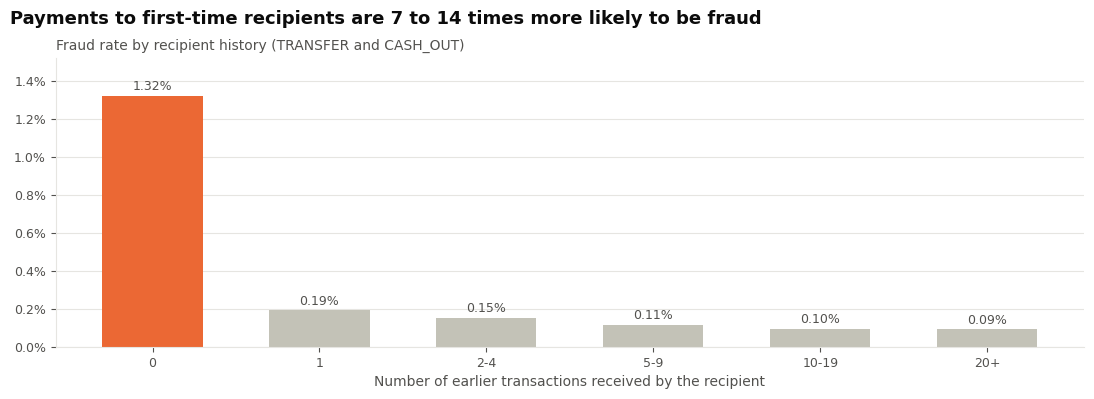

,transactions,frauds,fraud_rate,share_of_frauds
dest_prior_count,,,,
0,391463,5174,0.0132,0.6300
1,300301,576,0.0019,0.0701
2-4,639808,981,0.0015,0.1194
5-9,620356,713,0.0011,0.0868
10-19,544711,519,0.0010,0.0632
20+,273770,250,0.0009,0.0304


In [13]:
buckets = pd.cut(tc.dest_prior_count, [-1, 0, 1, 4, 9, 19, np.inf], labels=["0", "1", "2-4", "5-9", "10-19", "20+"])
rec = tc.groupby(buckets, observed=True).agg(transactions=("isFraud", "size"), frauds=("isFraud", "sum"),
                                             fraud_rate=("isFraud", "mean"))
rec["share_of_frauds"] = rec.frauds / rec.frauds.sum()

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(rec.index.astype(str), rec.fraud_rate * 100, color=[FRAUD] + [MUTED] * (len(rec) - 1), width=0.6)
for i, r in enumerate(rec.fraud_rate):
    ax.text(i, r * 100 + 0.03, f"{r:.2%}", ha="center", fontsize=9, color=INK2)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, rec.fraud_rate.max() * 100 * 1.15)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Number of earlier transactions received by the recipient")
ax.set_title("Fraud rate by recipient history (TRANSFER and CASH_OUT)")
fig.tight_layout(); headline(fig, "Payments to first-time recipients are 7 to 14 times more likely to be fraud"); save(fig, "fraud_rate_by_recipient_history"); plt.show()
rec

A first-time recipient is involved in 63% of frauds but only 14% of legitimate transactions. The fraud rate is 1.32% when the recipient has never received money before, compared with 0.09% to 0.19% for recipients with a history. This is consistent with funds being moved to newly created mule accounts. Because the feature uses earlier transactions only, it is available at scoring time and does not leak the label.

## Discriminative power and redundancy of candidate features

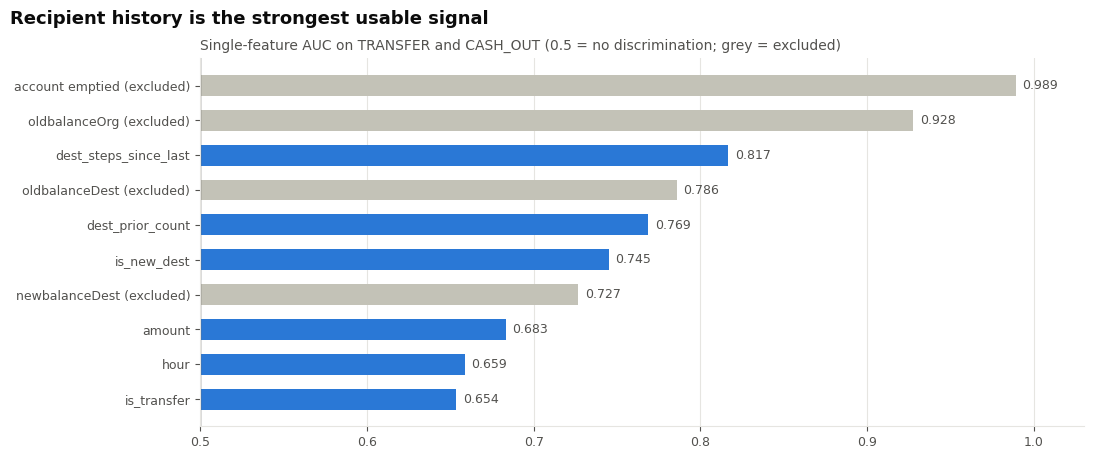

account emptied (excluded)   0.9890
oldbalanceOrg (excluded)     0.9280
dest_steps_since_last        0.8170
oldbalanceDest (excluded)    0.7860
dest_prior_count             0.7690
is_new_dest                  0.7450
newbalanceDest (excluded)    0.7270
amount                       0.6830
hour                         0.6590
is_transfer                  0.6540
dtype: float64

In [14]:
tc["is_transfer"] = (tc.type == "TRANSFER").astype("int8")
tc["dest_steps_since_last_filled"] = tc.dest_steps_since_last.fillna(9999)
candidates = {
    "dest_steps_since_last": tc.dest_steps_since_last_filled,
    "dest_prior_count": tc.dest_prior_count,
    "is_new_dest": tc.is_new_dest,
    "amount": tc.amount,
    "hour": tc.hour,
    "is_transfer": tc.is_transfer,
    "oldbalanceOrg (excluded)": tc.oldbalanceOrg,
    "oldbalanceDest (excluded)": tc.oldbalanceDest,
    "newbalanceDest (excluded)": tc.newbalanceDest,
    "account emptied (excluded)": (tc.oldbalanceOrg == tc.amount).astype("int8"),
}
auc = pd.Series({name: max(a, 1 - a) for name, a in
                 ((n, roc_auc_score(tc.isFraud, s)) for n, s in candidates.items())}).sort_values()

fig, ax = plt.subplots(figsize=(11, 4.4))
colors = [MUTED if "excluded" in n else LEGIT for n in auc.index]
ax.barh(auc.index, auc - 0.5, left=0.5, color=colors, height=0.6)
for i, v in enumerate(auc):
    ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=9, color=INK2)
ax.set_xlim(0.5, 1.03)
ax.axvline(0.5, color=INK2, lw=1)
ax.grid(axis="y", visible=False)
ax.set_title("Single-feature AUC on TRANSFER and CASH_OUT (0.5 = no discrimination; grey = excluded)")
fig.tight_layout(); headline(fig, "Recipient history is the strongest usable signal"); save(fig, "feature_auc"); plt.show()
auc.sort_values(ascending=False).round(3)

Among the usable features, the recipient-based features discriminate best (AUC 0.75 to 0.82), followed by amount, hour and type (0.65 to 0.68). The leaking balance features reach up to 0.989 and are shown only for reference. The usable AUCs are moderate, which is expected for a realistic fraud signal; the model will rely on combining them with the synthetic fields.

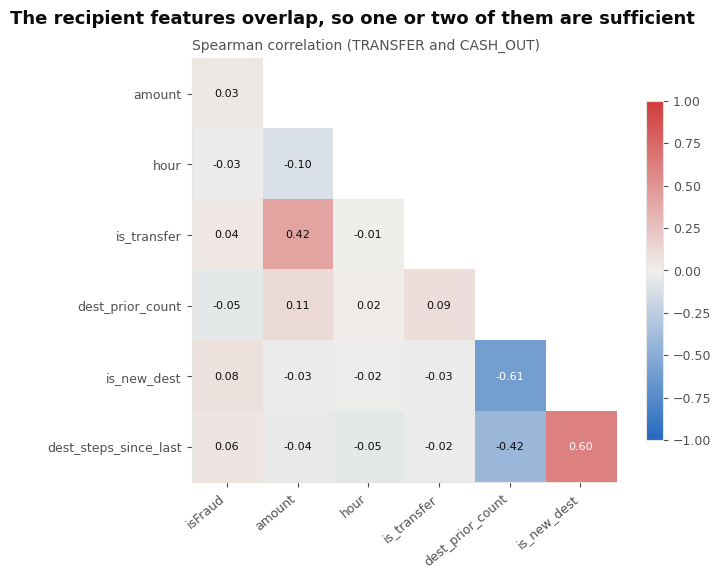

,isFraud,amount,hour,is_transfer,dest_prior_count,is_new_dest,dest_steps_since_last
isFraud,1.0000,0.0300,-0.0300,0.0400,-0.0500,0.0800,0.0600
amount,0.0300,1.0000,-0.1000,0.4200,0.1100,-0.0300,-0.0400
hour,-0.0300,-0.1000,1.0000,-0.0100,0.0200,-0.0200,-0.0500
is_transfer,0.0400,0.4200,-0.0100,1.0000,0.0900,-0.0300,-0.0200
dest_prior_count,-0.0500,0.1100,0.0200,0.0900,1.0000,-0.6100,-0.4200
is_new_dest,0.0800,-0.0300,-0.0200,-0.0300,-0.6100,1.0000,0.6000
dest_steps_since_last,0.0600,-0.0400,-0.0500,-0.0200,-0.4200,0.6000,1.0000


In [15]:
corr_cols = ["isFraud", "amount", "hour", "is_transfer", "dest_prior_count", "is_new_dest", "dest_steps_since_last_filled"]
corr = tc[corr_cols].corr(method="spearman").rename(index={"dest_steps_since_last_filled": "dest_steps_since_last"},
                                                    columns={"dest_steps_since_last_filled": "dest_steps_since_last"})
from matplotlib.colors import LinearSegmentedColormap
diverging = LinearSegmentedColormap.from_list("blue_grey_red", ["#256abf", "#f0efec", "#d03b3b"])

lower = corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1)).iloc[1:, :-1]
diverging.set_bad("white")
fig, ax = plt.subplots(figsize=(7.5, 5.6))
im = ax.imshow(lower, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(lower.shape[1]), lower.columns, rotation=40, ha="right")
ax.set_yticks(range(lower.shape[0]), lower.index)
ax.grid(False)
for i in range(lower.shape[0]):
    for j in range(lower.shape[1]):
        v = lower.iloc[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 0.55 else INK)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Spearman correlation (TRANSFER and CASH_OUT)")
fig.tight_layout(); headline(fig, "The recipient features overlap, so one or two of them are sufficient"); save(fig, "feature_correlation"); plt.show()
corr.round(2)

The three recipient features are correlated with each other (absolute Spearman correlation between 0.42 and 0.61), since `is_new_dest` is the zero case of `dest_prior_count` and the missing case of `dest_steps_since_last`. Amount and type are also related (0.42), as transfers tend to be larger. Feature selection is expected to retain one or two of them. Correlations with `isFraud` are small in absolute terms because of the class imbalance; the AUC above is a better measure of separation.

## Proposed split points

The split is time-based: train, then validation, then test, then the stream used for replay. Option A places cut points at 60%, 75% and 90% of the cumulative number of transactions; option B uses the cumulative number of frauds instead.

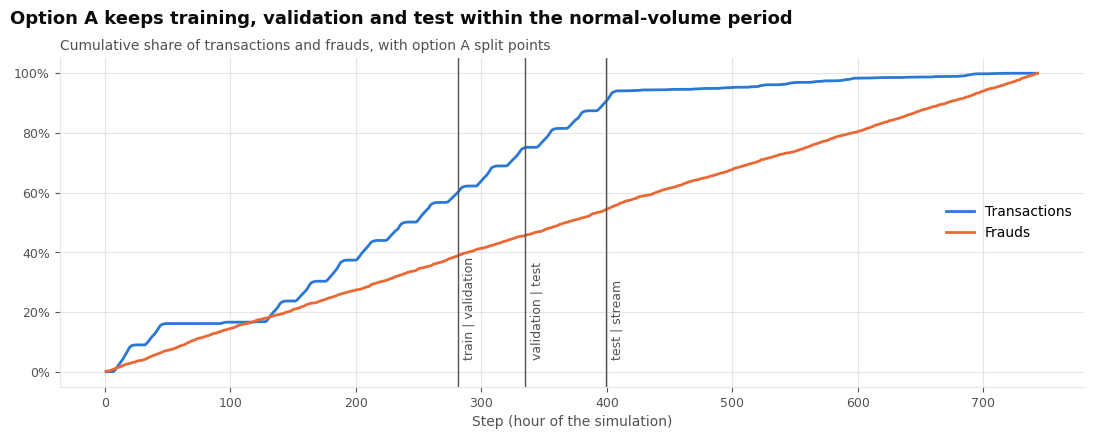

Option A (cumulative transactions):


,first_step,last_step,transactions,frauds,fraud_rate,share_of_transactions,share_of_frauds
step,,,,,,,
train,1,281,3820599,3193,0.0008,0.6005,0.3888
validation,282,335,961244,556,0.0006,0.1511,0.0677
test,336,399,974277,712,0.0007,0.1531,0.0867
stream,400,743,606500,3752,0.0062,0.0953,0.4568


Option B (cumulative frauds):


,first_step,last_step,transactions,frauds,fraud_rate,share_of_transactions,share_of_frauds
step,,,,,,,
train,1,439,6009593,4931,0.0008,0.9445,0.6004
validation,440,558,159102,1234,0.0078,0.0250,0.1502
test,559,671,127323,1240,0.0097,0.0200,0.1510
stream,672,743,66602,808,0.0121,0.0105,0.0984


In [16]:
by_step = df.groupby("step").agg(n=("isFraud", "size"), n_fraud=("isFraud", "sum"))
cum = by_step.cumsum() / by_step.sum()

def cuts(col):
    return [int(cum.index[np.searchsorted(cum[col].to_numpy(), s)]) for s in (.60, .75, .90)]

def split_table(cut_points):
    labels = pd.cut(df.step, [0, *cut_points, df.step.max()], labels=["train", "validation", "test", "stream"])
    t = df.groupby(labels, observed=True).agg(first_step=("step", "min"), last_step=("step", "max"),
                                              transactions=("isFraud", "size"), frauds=("isFraud", "sum"),
                                              fraud_rate=("isFraud", "mean"))
    t["share_of_transactions"] = t.transactions / len(df)
    t["share_of_frauds"] = t.frauds / n_fraud
    return t

a_cuts, b_cuts = cuts("n"), cuts("n_fraud")

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(cum.index, cum.n * 100, color=LEGIT, label="Transactions")
ax.plot(cum.index, cum.n_fraud * 100, color=FRAUD, label="Frauds")
for c, name in zip(a_cuts, ["train | validation", "validation | test", "test | stream"]):
    ax.axvline(c, color=INK2, lw=1)
    ax.text(c + 4, 4, name, rotation=90, fontsize=9, color=INK2, va="bottom")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Step (hour of the simulation)")
ax.set_title("Cumulative share of transactions and frauds, with option A split points")
ax.legend(loc="center right")
fig.tight_layout(); headline(fig, "Option A keeps training, validation and test within the normal-volume period"); save(fig, "split_cumulative_share"); plt.show()

print("Option A (cumulative transactions):"); display(split_table(a_cuts))
print("Option B (cumulative frauds):"); display(split_table(b_cuts))

Option A yields training (steps 1 to 281), validation (282 to 335) and test (336 to 399) sets drawn from the same high-volume period, with 556 and 712 frauds in validation and test. The stream (steps 400 to 743) holds 45.7% of the frauds at a fraud rate about eight times higher, which provides a genuine shift for the monitoring component. Option B balances the number of frauds, but its validation and test sets contain only 2% to 2.5% of the transactions with a fraud rate about ten times that of training, so they would no longer represent the training distribution. Option A is therefore proposed. Evaluation and monitoring should expect precision on the stream to differ markedly from validation because of this prior shift.

## Implications for the next steps

| Area | Implication |
|---|---|
| Data generation | Generate a `customer_id`, since `nameOrig` is almost always unique. Derive time of day from `step % 24`. Keep fraud and legitimate distributions of synthetic fields overlapping. |
| Cleaning | Decide on the 16 zero-amount frauds. Keep amount outliers (fraud rate 4.0% among them) and the 10 million cap, documented as a simulation limit. |
| Features | Use `log(amount)`, cyclical hour, `is_transfer` and recipient history computed from earlier transactions. Exclude the balance columns, raw `step`, `nameOrig` and `isFlaggedFraud`. |
| Evaluation | Handle a 336 to 1 imbalance within TRANSFER and CASH_OUT. Report recall by count and by value. Use `isFlaggedFraud` (16 flags, recall 0.19%) as a naive baseline. |
| Split and monitoring | Use option A. The stream contains a real increase in the fraud rate after step 400. |